# 95 · The FAST tokenizer from scratch: DCT compression of action chunks + byte-pair encoding

In [1]:
import os, collections, numpy as np, matplotlib.pyplot as plt
from scipy.fft import dct, idct
from vlacourse import list_episodes, load_episode

DATA = os.path.abspath("../data/tabletop_panda_v1")
H = 16

def chunks(eps, H=H, stride=4):
    out = []
    for e in eps:
        a = e[:, :6]
        for t in range(0, len(a) - H + 1, stride):
            out.append(a[t:t + H])
    return np.array(out)

class FastTokenizer:
    """Per-dimension normalization -> DCT along time -> scale & round -> flatten (frequency-major) -> BPE."""

    def __init__(self, train_chunks, scale=10.0, vocab_size=1024):
        self.lo, self.hi = np.percentile(train_chunks.reshape(-1, 6), 1, 0), np.percentile(train_chunks.reshape(-1, 6), 99, 0)
        self.scale, self.merges = scale, {}
        seqs = [self._ints(c) for c in train_chunks]
        self.base = sorted({i for s in seqs for i in s})
        self.vocab = {b: k for k, b in enumerate(self.base)}
        seqs = [[self.vocab[i] for i in s] for s in seqs]
        nxt = len(self.vocab)
        while nxt < vocab_size:
            pairs = collections.Counter(p for s in seqs for p in zip(s, s[1:]))
            if not pairs:
                break
            best, n = pairs.most_common(1)[0]
            if n < 2:
                break
            self.merges[best] = nxt
            seqs = [self._merge(s, best, nxt) for s in seqs]
            nxt += 1
        self.inv_vocab = {k: b for b, k in self.vocab.items()}

    def _norm(self, c):
        return 2 * (c - self.lo) / (self.hi - self.lo) - 1

    def _ints(self, c):
        coeff = dct(self._norm(c), axis=0, norm="ortho")
        return np.round(coeff * self.scale).astype(int).reshape(-1).tolist()

    @staticmethod
    def _merge(s, pair, new):
        out, i = [], 0
        while i < len(s):
            if i + 1 < len(s) and (s[i], s[i + 1]) == pair:
                out.append(new); i += 2
            else:
                out.append(s[i]); i += 1
        return out

    def encode(self, c):
        s = [self.vocab.get(i, self.vocab[min(self.base, key=lambda b: abs(b - i))]) for i in self._ints(c)]
        for pair, new in self.merges.items():
            s = self._merge(s, pair, new)
        return s

    def decode(self, tokens):
        inv = {v: k for k, v in self.merges.items()}
        def expand(t):
            return expand(inv[t][0]) + expand(inv[t][1]) if t in inv else [self.inv_vocab[t]]
        ints = np.array([i for t in tokens for i in expand(t)], float).reshape(H, 6)
        return (idct(ints / self.scale, axis=0, norm="ortho") + 1) / 2 * (self.hi - self.lo) + self.lo

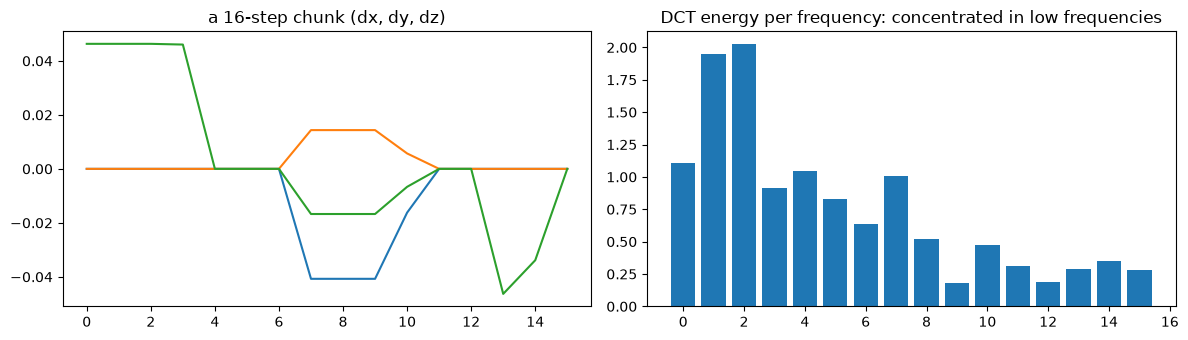

In [2]:
eps = [load_episode(p)["action"] for p in list_episodes(DATA)]
train, test = chunks(eps[:160]), chunks(eps[160:])
c = train[50]
coeff = dct(2 * (c - train.reshape(-1, 6).min(0)) / np.ptp(train.reshape(-1, 6), 0).clip(1e-8) - 1, axis=0, norm="ortho")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(c[:, :3]); ax[0].set_title("a 16-step chunk (dx, dy, dz)"); ax[1].bar(range(H), np.abs(coeff[:, :3]).sum(1)); ax[1].set_title("DCT energy per frequency: concentrated in low frequencies")
plt.tight_layout(); plt.show()

In [3]:
fast = FastTokenizer(train, scale=10.0, vocab_size=1024)
print(f"base symbols {len(fast.base)}, BPE merges {len(fast.merges)}")
lens = [len(fast.encode(c)) for c in test]
err = np.array([np.abs(fast.decode(fast.encode(c)) - c).mean(0) for c in test[:300]])
naive_tokens = H * 6
print(f"naive per-dimension binning: {naive_tokens} tokens per chunk")
print(f"FAST: {np.mean(lens):.1f} ± {np.std(lens):.1f} tokens per chunk  ({naive_tokens / np.mean(lens):.1f}x compression)")
print(f"FAST round-trip MAE: translation {err[:, :3].mean() * 1000:.3f} mm, rotation {err[:, 3:].mean() * 1000:.3f} mrad")

/tmp/ipykernel_1122292/2063557099.py:40: RuntimeWarning: invalid value encountered in divide
  return 2 * (c - self.lo) / (self.hi - self.lo) - 1
/tmp/ipykernel_1122292/2063557099.py:44: RuntimeWarning: invalid value encountered in cast
  return np.round(coeff * self.scale).astype(int).reshape(-1).tolist()


base symbols 58, BPE merges 966


naive per-dimension binning: 96 tokens per chunk
FAST: 22.5 ± 10.4 tokens per chunk  (4.3x compression)
FAST round-trip MAE: translation 0.803 mm, rotation 1.381 mrad


/tmp/ipykernel_1122292/2063557099.py:40: RuntimeWarning: invalid value encountered in divide
  return 2 * (c - self.lo) / (self.hi - self.lo) - 1
/tmp/ipykernel_1122292/2063557099.py:44: RuntimeWarning: invalid value encountered in cast
  return np.round(coeff * self.scale).astype(int).reshape(-1).tolist()


scale   2:   6.5 tokens/chunk, translation MAE 3.063 mm


scale   5:  14.6 tokens/chunk, translation MAE 1.461 mm


scale  10:  21.6 tokens/chunk, translation MAE 0.792 mm


scale  20:  29.5 tokens/chunk, translation MAE 0.388 mm


scale  40:  36.0 tokens/chunk, translation MAE 0.199 mm


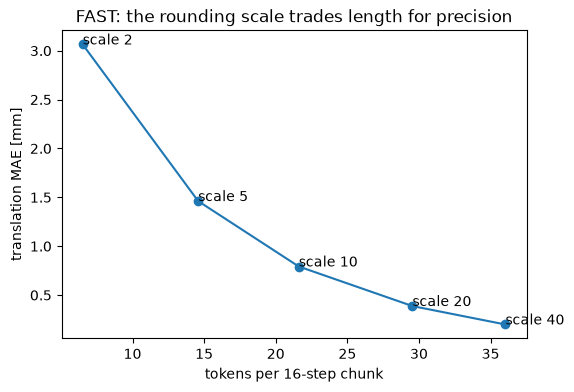

In [4]:
rows = []
for s in [2, 5, 10, 20, 40]:
    f = FastTokenizer(train[:2000], scale=s, vocab_size=1024)
    L = np.mean([len(f.encode(c)) for c in test[:200]]); e = np.mean([np.abs(f.decode(f.encode(c)) - c)[:, :3].mean() for c in test[:200]]) * 1000
    rows.append((s, L, e)); print(f"scale {s:3d}: {L:5.1f} tokens/chunk, translation MAE {e:.3f} mm")
rows = np.array(rows)
plt.figure(figsize=(6, 4)); plt.plot(rows[:, 1], rows[:, 2], "o-")
for s, L, e in rows:
    plt.annotate(f"scale {s:.0f}", (L, e))
plt.xlabel("tokens per 16-step chunk"); plt.ylabel("translation MAE [mm]"); plt.title("FAST: the rounding scale trades length for precision"); plt.show()